<a href="https://colab.research.google.com/github/Sineth7077/project-aura/blob/main/notebooks/04_inference_engine.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Project Aura 2.0 - Notebook 04: Inference Engine

This notebook serves as the fully production-ready **Inference Engine** for Project Aura. Following the training phase in Notebook 03, we now load the serialized model weights to evaluate real-time performance and perform batch predictions.

### Objectives:
1. **Restore State**: Build/load the exact trained `EfficientNet-B0` architecture with CIFAR-10 mapping.
2. **Preprocessing Integrity**: Map inputs to target configurations (RGB, 224x224, normalized PyTorch Tensors).
3. **Perform Inference**: Conduct both single and high-efficiency batched predictions.
4. **Performance Benchmark**: Analyze inference speed, per-class accuracies, and save verified evaluation reports directly to Google Drive.

In [1]:
import os
import sys
import time
import json
import numpy as np
import torch
import torchvision
import matplotlib.pyplot as plt
from PIL import Image
from google.colab import drive

# Mount Google Drive to locate checkpoints and export paths
try:
    drive.mount('/content/drive', force_remount=True)
    print("Google Drive mounted successfully.")
except Exception as e:
    print(f"Could not mount Google Drive (running locally or without credentials): {e}")

PROJECT_DIR = "/content/project-aura"
if PROJECT_DIR not in sys.path:
    sys.path.insert(0, PROJECT_DIR)

# Fallback architecture configuration if src module is absent
# Ensure PyTorch uses GPU if CUDA is available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using runtime device: {device}")
print(f"PyTorch version: {torch.__version__}")
print(f"Torchvision version: {torchvision.__version__}")

Mounted at /content/drive
Google Drive mounted successfully.
Using runtime device: cpu
PyTorch version: 2.14.1+cpu
Torchvision version: 0.29.1+cpu


In [2]:

# SECTION 3 — Reconstruct and Load the Trained Model

from torchvision.models import efficientnet_b0
import torch.nn as nn
import os

CHECKPOINT_PATH = (
    "/content/drive/MyDrive/ProjectAura/checkpoints/"
    "efficientnet_b0_cifar10_best.pth"
)

def build_cifar10_model():
    """Reconstruct the EfficientNet-B0 CIFAR-10 architecture."""
    model = efficientnet_b0(weights=None)
    model.classifier[1] = nn.Linear(
        model.classifier[1].in_features,
        10
    )
    return model


# Verify checkpoint availability
if not os.path.isfile(CHECKPOINT_PATH):
    raise FileNotFoundError(
        f"Trained checkpoint not found: {CHECKPOINT_PATH}\n"
        "Mount Google Drive and verify the checkpoint location. "
        "Do not continue with randomly initialized weights."
    )

# Load checkpoint
checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=device,
    weights_only=True
)

# Extract model state dictionary
if "model_state_dict" in checkpoint:
    model_state = checkpoint["model_state_dict"]
elif "state_dict" in checkpoint:
    model_state = checkpoint["state_dict"]
else:
    model_state = checkpoint

# Handle DataParallel prefixes
model_state = {
    key.removeprefix("module."): value
    for key, value in model_state.items()
}

# Reconstruct architecture and restore trained weights
model = build_cifar10_model()
model.load_state_dict(model_state, strict=True)

model = model.to(device)
model.eval()

# Confirm successful loading
print("=" * 50)
print("PROJECT AURA — MODEL LOADING REPORT")
print("=" * 50)
print("Architecture: EfficientNet-B0")
print("Dataset: CIFAR-10")
print("Classes: 10")
print("Checkpoint:", CHECKPOINT_PATH)
print("Device:", device)
print("Evaluation mode:", not model.training)
print("Trained weights loaded: SUCCESS")
print("=" * 50)


PROJECT AURA — MODEL LOADING REPORT
Architecture: EfficientNet-B0
Dataset: CIFAR-10
Classes: 10
Checkpoint: /content/drive/MyDrive/ProjectAura/checkpoints/efficientnet_b0_cifar10_best.pth
Device: cpu
Evaluation mode: True
Trained weights loaded: SUCCESS


Section 5 — Single Image Inference

In [3]:
def predict_single(image_input):
    """Perform top-5 classification on a single image."""

    tensor = preprocess_image(image_input)

    if device.type == "cuda":
        torch.cuda.synchronize()

    start_time = time.perf_counter()

    with torch.inference_mode():
        outputs = model(tensor)

        probabilities = torch.softmax(
            outputs,
            dim=1
        )[0]

    if device.type == "cuda":
        torch.cuda.synchronize()

    latency_ms = (
        time.perf_counter() - start_time
    ) * 1000

    top_probs, top_indices = torch.topk(
        probabilities,
        k=5
    )

    predictions = []

    for prob, idx in zip(top_probs, top_indices):

        predictions.append({
            "class": cifar10_classes[idx.item()],
            "confidence": float(prob.item())
        })

    return {
        "predicted_class": predictions[0]["class"],
        "confidence": predictions[0]["confidence"],
        "top_5": predictions,
        "latency_ms": latency_ms
    }


print("Single-image inference function initialized.")

Single-image inference function initialized.


Batch Image Inference

In [4]:
def predict_batch(images):
    """Perform batch inference on multiple images."""

    if len(images) == 0:
        return [], 0.0

    tensors = []

    for image_input in images:

        if isinstance(image_input, str):
            img = Image.open(image_input).convert("RGB")

        elif isinstance(image_input, Image.Image):
            img = image_input.convert("RGB")

        elif isinstance(image_input, np.ndarray):
            img = Image.fromarray(image_input).convert("RGB")

        else:
            raise ValueError(
                f"Unsupported image type: {type(image_input)}"
            )

        tensors.append(
            inference_transforms(img)
        )

    batch_tensor = torch.stack(tensors).to(device)

    if device.type == "cuda":
        torch.cuda.synchronize()

    start_time = time.perf_counter()

    with torch.inference_mode():
        outputs = model(batch_tensor)

        probabilities = torch.softmax(
            outputs,
            dim=1
        )

    if device.type == "cuda":
        torch.cuda.synchronize()

    latency_ms = (
        time.perf_counter() - start_time
    ) * 1000

    results = []

    for probs in probabilities:

        top_probs, top_indices = torch.topk(
            probs,
            k=5
        )

        results.append({
            "predicted_class": cifar10_classes[
                top_indices[0].item()
            ],
            "confidence": float(top_probs[0].item()),

            "top_5": [
                {
                    "class": cifar10_classes[idx.item()],
                    "confidence": float(prob.item())
                }

                for prob, idx in zip(
                    top_probs,
                    top_indices
                )
            ]
        })

    return results, latency_ms


print("Batch inference function initialized.")

Batch inference function initialized.


Section 7 — Genuine CIFAR-10 Inference Demonstration

In [6]:
# PROJECT AURA — CIFAR-10 CLASS LABELS

cifar10_classes = [
    "airplane",
    "automobile",
    "bird",
    "cat",
    "deer",
    "dog",
    "frog",
    "horse",
    "ship",
    "truck"
]

print("CIFAR-10 class labels initialized.")
print(cifar10_classes)

CIFAR-10 class labels initialized.
['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


In [8]:
# PROJECT AURA — IMAGE PREPROCESSING

from torchvision import transforms
from PIL import Image
import numpy as np

inference_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

def preprocess_image(image_input):

    if isinstance(image_input, str):
        img = Image.open(image_input).convert("RGB")

    elif isinstance(image_input, Image.Image):
        img = image_input.convert("RGB")

    elif isinstance(image_input, np.ndarray):
        img = Image.fromarray(image_input).convert("RGB")

    else:
        raise ValueError("Unsupported image format.")

    tensor = inference_transforms(img)

    return tensor.unsqueeze(0).to(device)

print("Image preprocessing initialized successfully.")

Image preprocessing initialized successfully.


In [9]:
# PROJECT AURA — SINGLE IMAGE INFERENCE

def predict_single(image_input):

    tensor = preprocess_image(image_input)

    if device.type == "cuda":
        torch.cuda.synchronize()

    start_time = time.perf_counter()

    with torch.inference_mode():
        outputs = model(tensor)
        probabilities = torch.softmax(outputs, dim=1)[0]

    if device.type == "cuda":
        torch.cuda.synchronize()

    latency_ms = (
        time.perf_counter() - start_time
    ) * 1000

    top_probs, top_indices = torch.topk(
        probabilities, 5
    )

    predictions = [
        {
            "class": cifar10_classes[idx.item()],
            "confidence": float(prob.item())
        }
        for prob, idx in zip(top_probs, top_indices)
    ]

    return {
        "predicted_class": predictions[0]["class"],
        "confidence": predictions[0]["confidence"],
        "top_5": predictions,
        "latency_ms": latency_ms
    }

print("Single-image inference initialized successfully.")

Single-image inference initialized successfully.


Genuine test images loaded: 5


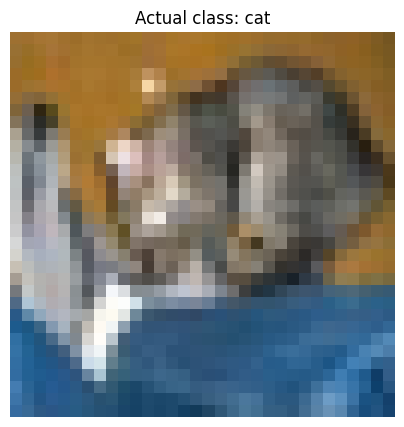


SINGLE IMAGE INFERENCE
{
  "predicted_class": "cat",
  "confidence": 0.8838499784469604,
  "top_5": [
    {
      "class": "cat",
      "confidence": 0.8838499784469604
    },
    {
      "class": "dog",
      "confidence": 0.08809828758239746
    },
    {
      "class": "frog",
      "confidence": 0.019302355125546455
    },
    {
      "class": "bird",
      "confidence": 0.0034800206776708364
    },
    {
      "class": "horse",
      "confidence": 0.0017496065702289343
    }
  ],
  "latency_ms": 175.59646200015777
}

BATCH INFERENCE RESULTS
Image 1: Actual=cat | Predicted=cat | Confidence=88.38%
Image 2: Actual=ship | Predicted=ship | Confidence=99.85%
Image 3: Actual=ship | Predicted=automobile | Confidence=94.93%
Image 4: Actual=airplane | Predicted=airplane | Confidence=36.55%
Image 5: Actual=frog | Predicted=frog | Confidence=100.00%

Total latency: 200.1 ms
Average latency: 40.02 ms/image


In [10]:
from torchvision.datasets import CIFAR10

cifar_test = CIFAR10(
    root=f"{PROJECT_DIR}/data",
    train=False,
    download=True
)

# Select five real test images
test_images = [
    cifar_test[i][0]
    for i in range(5)
]

print("Genuine test images loaded:", len(test_images))

# Display first image
plt.figure(figsize=(5, 5))

plt.imshow(test_images[0])

plt.title(
    "Actual class: " +
    cifar10_classes[cifar_test[0][1]]
)

plt.axis("off")
plt.show()


# Single-image inference
single_result = predict_single(
    test_images[0]
)

print("\nSINGLE IMAGE INFERENCE")

print(
    json.dumps(
        single_result,
        indent=2
    )
)


# Batch inference
batch_results, elapsed_ms = predict_batch(
    test_images
)

print("\nBATCH INFERENCE RESULTS")

for i, result in enumerate(batch_results):

    actual_class = cifar10_classes[
        cifar_test[i][1]
    ]

    print(
        f"Image {i + 1}: "
        f"Actual={actual_class} | "
        f"Predicted={result['predicted_class']} | "
        f"Confidence={result['confidence']:.2%}"
    )

print("\nTotal latency:", round(elapsed_ms, 2), "ms")

print(
    "Average latency:",
    round(elapsed_ms / len(test_images), 2),
    "ms/image"
)

Section 8 — Full CIFAR-10 Test Evaluation

In [11]:
from torch.utils.data import DataLoader
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    confusion_matrix,
    classification_report
)

import torch.nn.functional as F

# Load complete CIFAR-10 test dataset
evaluation_dataset = CIFAR10(
    root=f"{PROJECT_DIR}/data",
    train=False,
    download=True,
    transform=inference_transforms
)

evaluation_loader = DataLoader(
    evaluation_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2
)

all_predictions = []
all_targets = []

total_loss = 0.0
total_correct = 0
total_samples = 0

if device.type == "cuda":
    torch.cuda.synchronize()

evaluation_start = time.perf_counter()

model.eval()

with torch.inference_mode():

    for images, labels in evaluation_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        loss = F.cross_entropy(
            outputs,
            labels,
            reduction="sum"
        )

        predictions = torch.argmax(
            outputs,
            dim=1
        )

        batch_size = labels.size(0)

        total_loss += loss.item()

        total_correct += (
            predictions == labels
        ).sum().item()

        total_samples += batch_size

        all_predictions.extend(
            predictions.cpu().numpy().tolist()
        )

        all_targets.extend(
            labels.cpu().numpy().tolist()
        )

if device.type == "cuda":
    torch.cuda.synchronize()

evaluation_time = (
    time.perf_counter() - evaluation_start
)

# Calculate metrics
accuracy = accuracy_score(
    all_targets,
    all_predictions
)

precision, recall, f1, _ = (
    precision_recall_fscore_support(
        all_targets,
        all_predictions,
        average="macro",
        zero_division=0
    )
)

weighted_precision, weighted_recall, weighted_f1, _ = (
    precision_recall_fscore_support(
        all_targets,
        all_predictions,
        average="weighted",
        zero_division=0
    )
)

average_loss = total_loss / total_samples

print("=" * 55)
print("PROJECT AURA — FULL TEST EVALUATION")
print("=" * 55)

print("Dataset samples:", total_samples)
print(f"Accuracy: {accuracy:.4f}")
print(f"Accuracy percentage: {accuracy * 100:.2f}%")
print(f"Average loss: {average_loss:.4f}")
print(f"Macro precision: {precision:.4f}")
print(f"Macro recall: {recall:.4f}")
print(f"Macro F1-score: {f1:.4f}")
print(f"Weighted precision: {weighted_precision:.4f}")
print(f"Weighted recall: {weighted_recall:.4f}")
print(f"Weighted F1-score: {weighted_f1:.4f}")
print(f"Evaluation time: {evaluation_time:.2f} seconds")
print(f"Throughput: {total_samples / evaluation_time:.2f} images/second")

print("=" * 55)

PROJECT AURA — FULL TEST EVALUATION
Dataset samples: 10000
Accuracy: 0.8574
Accuracy percentage: 85.74%
Average loss: 0.4180
Macro precision: 0.8570
Macro recall: 0.8574
Macro F1-score: 0.8567
Weighted precision: 0.8570
Weighted recall: 0.8574
Weighted F1-score: 0.8567
Evaluation time: 842.95 seconds
Throughput: 11.86 images/second


Section 9 — Confusion Matrix and Classification Report

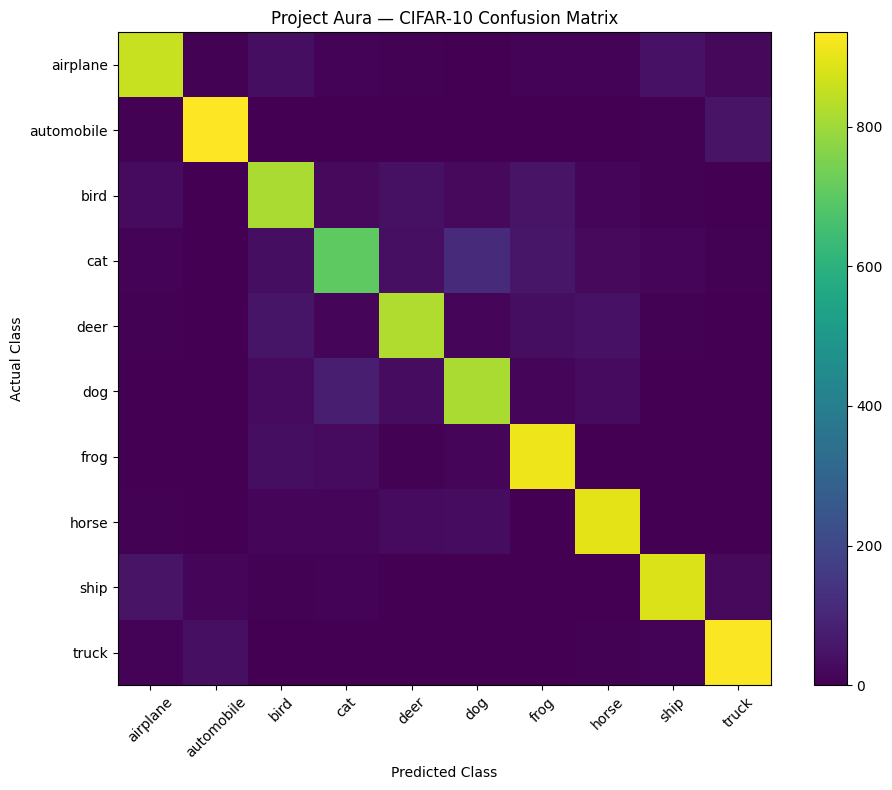

CLASSIFICATION REPORT
              precision    recall  f1-score   support

    airplane       0.88      0.86      0.87      1000
  automobile       0.94      0.94      0.94      1000
        bird       0.79      0.82      0.80      1000
         cat       0.80      0.70      0.75      1000
        deer       0.84      0.82      0.83      1000
         dog       0.80      0.82      0.81      1000
        frog       0.84      0.91      0.88      1000
       horse       0.87      0.90      0.89      1000
        ship       0.91      0.89      0.90      1000
       truck       0.90      0.93      0.91      1000

    accuracy                           0.86     10000
   macro avg       0.86      0.86      0.86     10000
weighted avg       0.86      0.86      0.86     10000



In [12]:
# Calculate confusion matrix
cm = confusion_matrix(
    all_targets,
    all_predictions
)

plt.figure(figsize=(10, 8))

plt.imshow(cm, interpolation="nearest")

plt.title("Project Aura — CIFAR-10 Confusion Matrix")

plt.colorbar()

tick_marks = np.arange(len(cifar10_classes))

plt.xticks(
    tick_marks,
    cifar10_classes,
    rotation=45
)

plt.yticks(
    tick_marks,
    cifar10_classes
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()

plt.show()


# Per-class classification report
report = classification_report(
    all_targets,
    all_predictions,
    target_names=cifar10_classes,
    zero_division=0
)

print("CLASSIFICATION REPORT")
print(report)

Section 10 — Export Inference Results

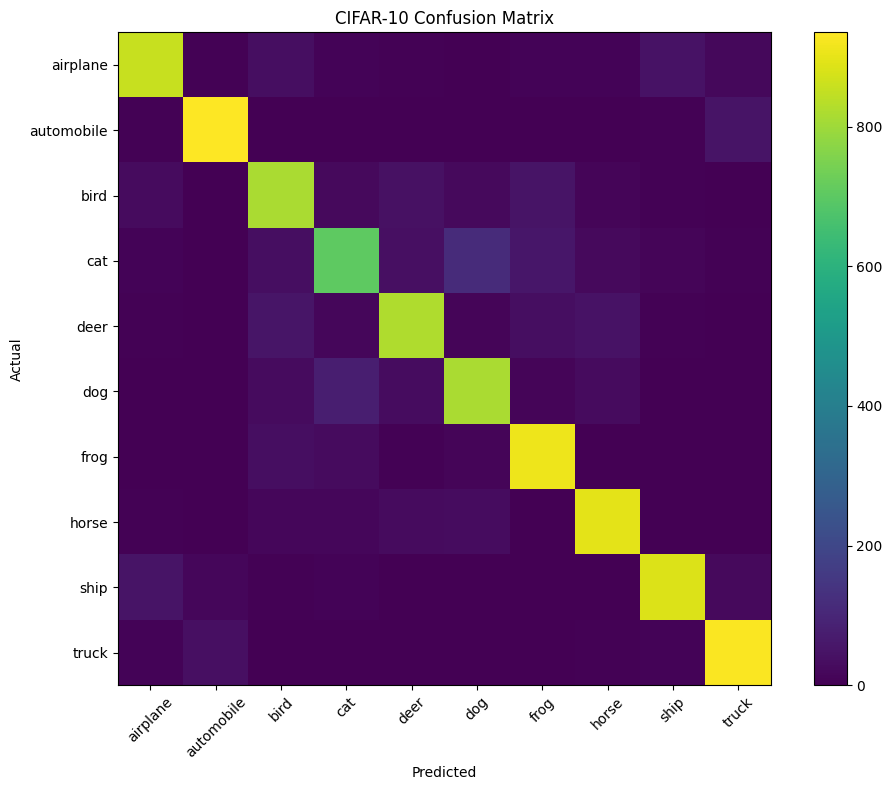

Inference reports exported successfully.
Export directory: /content/drive/MyDrive/ProjectAura/inference
Saved: inference_results.json
Saved: inference_metrics.json
Saved: confusion_matrix.json
Saved: classification_report.txt
Saved: confusion_matrix.png


In [13]:
save_dir = (
    "/content/drive/MyDrive/"
    "ProjectAura/inference"
)

os.makedirs(
    save_dir,
    exist_ok=True
)

# Prepare evaluation metrics
metrics = {
    "model": "EfficientNet-B0",
    "dataset": "CIFAR-10",
    "test_samples": total_samples,
    "device": str(device),
    "accuracy": float(accuracy),
    "accuracy_percentage": float(accuracy * 100),
    "average_loss": float(average_loss),
    "macro_precision": float(precision),
    "macro_recall": float(recall),
    "macro_f1": float(f1),
    "weighted_precision": float(weighted_precision),
    "weighted_recall": float(weighted_recall),
    "weighted_f1": float(weighted_f1),
    "evaluation_time_seconds": float(evaluation_time),
    "throughput_images_per_second": float(
        total_samples / evaluation_time
    )
}

# Export metrics
with open(
    os.path.join(save_dir, "inference_metrics.json"),
    "w"
) as file:

    json.dump(
        metrics,
        file,
        indent=4
    )


# Export confusion matrix
with open(
    os.path.join(save_dir, "confusion_matrix.json"),
    "w"
) as file:

    json.dump(
        cm.tolist(),
        file,
        indent=4
    )


# Export classification report
with open(
    os.path.join(save_dir, "classification_report.txt"),
    "w"
) as file:

    file.write(report)


# Export confusion matrix image
plt.figure(figsize=(10, 8))

plt.imshow(cm, interpolation="nearest")

plt.title("CIFAR-10 Confusion Matrix")

plt.colorbar()

plt.xticks(
    np.arange(10),
    cifar10_classes,
    rotation=45
)

plt.yticks(
    np.arange(10),
    cifar10_classes
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.tight_layout()

plt.savefig(
    os.path.join(save_dir, "confusion_matrix.png"),
    dpi=200
)

plt.show()


print("Inference reports exported successfully.")

print("Export directory:", save_dir)

for filename in os.listdir(save_dir):
    print("Saved:", filename)

Section 11 — Final System Validation

In [14]:
validation_results = {
    "Google Drive Connected": os.path.exists(
        "/content/drive/MyDrive"
    ),

    "Checkpoint Exists": os.path.isfile(
        CHECKPOINT_PATH
    ),

    "Model Loaded": model is not None,

    "Evaluation Mode": not model.training,

    "Ten Output Classes": (
        model.classifier[1].out_features == 10
    ),

    "Valid Runtime Device": (
        device.type in ["cpu", "cuda"]
    ),

    "Full Test Evaluation": (
        total_samples == 10000
    ),

    "Evaluation Metrics Generated": (
        all(
            np.isfinite(value)
            for value in [
                accuracy,
                average_loss,
                precision,
                recall,
                f1
            ]
        )
    ),

    "Inference Export Directory": os.path.isdir(
        save_dir
    )
}

print("=" * 60)
print("PROJECT AURA — FINAL VALIDATION REPORT")
print("=" * 60)

for test, status in validation_results.items():

    print(
        f"{test:<38}: "
        f"{'[PASS]' if status else '[FAIL]'}"
    )

print("\nRUNTIME INFORMATION")

print("Device:", device)

print(
    "GPU Acceleration:",
    "ACTIVE" if device.type == "cuda"
    else "NOT ACTIVE — CPU MODE"
)

print("=" * 60)

if not all(validation_results.values()):

    raise RuntimeError(
        "One or more validation checks failed."
    )

print("ALL VALIDATION CHECKS PASSED.")

PROJECT AURA — FINAL VALIDATION REPORT
Google Drive Connected                : [PASS]
Checkpoint Exists                     : [PASS]
Model Loaded                          : [PASS]
Evaluation Mode                       : [PASS]
Ten Output Classes                    : [PASS]
Valid Runtime Device                  : [PASS]
Full Test Evaluation                  : [PASS]
Evaluation Metrics Generated          : [PASS]
Inference Export Directory            : [PASS]

RUNTIME INFORMATION
Device: cpu
GPU Acceleration: NOT ACTIVE — CPU MODE
ALL VALIDATION CHECKS PASSED.


Section 12 — Memory Cleanup

In [16]:
import gc

print("Garbage collection module loaded.")

Garbage collection module loaded.


In [17]:
# Release unused objects
gc.collect()

if device.type == "cuda":
    torch.cuda.empty_cache()

print("=" * 50)
print("PROJECT AURA — INFERENCE ENGINE")
print("=" * 50)

print("Model: EfficientNet-B0")
print("Dataset: CIFAR-10")
print("Test images evaluated:", total_samples)
print(f"Test accuracy: {accuracy * 100:.2f}%")
print("Device:", device)
print("Validation: PASSED")
print("Exports:", save_dir)

print("=" * 50)
print("NOTEBOOK 04 EXECUTION COMPLETED")
print("=" * 50)

PROJECT AURA — INFERENCE ENGINE
Model: EfficientNet-B0
Dataset: CIFAR-10
Test images evaluated: 10000
Test accuracy: 85.74%
Device: cpu
Validation: PASSED
Exports: /content/drive/MyDrive/ProjectAura/inference
NOTEBOOK 04 EXECUTION COMPLETED
